# Component 3: Explainable AI and Severity: results notebook
**Project J-26-CS-314** | S.M.K.G.M.M. Sasangith (IT23348066)

Loads the trained stand-in detector (`models/detector.joblib`, trained on CICIoMT2024 with `train_standin.py`) and evaluates Component 3 on the real test file: detector accuracy, SHAP explanations, severity decisions with the life-critical override, and processing time.

## Cell 1: Import Libraries

In [1]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# EDIT these two paths if your folders are different
PROJECT  = os.environ.get("C3_NB_PROJECT",  r"C:\Users\Menuka\Desktop\j26-CS-314\c3_xai_severity")
TEST_CSV = os.environ.get("C3_NB_TEST_CSV", r"C:\Users\Menuka\Desktop\dataset\archive (1)\test_iomt.csv")

os.chdir(PROJECT)
sys.path.insert(0, PROJECT)

from src import config, taxonomy
from src.contract_loader import FEATURES, DEVICES
from src.explain import Explainer
from src.severity import SeverityEngine
from train_standin import load_big_csv

print("Project folder:", os.getcwd())
print("Contract features:", len(FEATURES))

c:\Users\Menuka\Desktop\Component 3\Component3_Scaffold\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project folder: C:\Users\Menuka\Desktop\j26-CS-314\c3_xai_severity
Contract features: 45


## Cell 2: Load Detector Model and Test Dataset
The test file is large, so it is read in chunks and at most 2,000 rows per attack class are kept. Short dataset labels (e.g. `DDoS SYN`) are mapped to the contract class names.

In [2]:
model = joblib.load(config.MODEL_PATH)
print("Detector classes:", len(model.classes_))
test = load_big_csv(TEST_CSV, "label", per_class=2000)
print("\nRows loaded:", len(test))

Detector classes: 18
rows kept per label:
label
TCP_IP-DDoS-TCP            2000
TCP_IP-DoS-UDP             2000
MQTT-DDoS-Publish_Flood    2000
TCP_IP-DoS-ICMP            2000
Recon-Port_Scan            2000
TCP_IP-DDoS-UDP            2000
MQTT-DoS-Connect_Flood     2000
Recon-OS_Scan              2000
TCP_IP-DoS-SYN             2000
TCP_IP-DoS-TCP             2000
Benign                     2000
MQTT-DoS-Publish_Flood     2000
TCP_IP-DDoS-ICMP           2000
TCP_IP-DDoS-SYN            2000
MQTT-Malformed_Data        1747
ARP_Spoofing               1744
Recon-VulScan              1034
Recon-Ping_Sweep            186

Rows loaded: 32711


## Cell 3: Preprocessing
Remove infinite or missing values, then split into the 45 contract features (X) and the attack label (y).

In [3]:
before = len(test)
test = test.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES)
X_test, y_test = test[FEATURES], test["label"]
print(f"Rows before: {before} | after cleaning: {len(test)} | removed: {before - len(test)}")
print("Feature matrix:", X_test.shape)

Rows before: 32711 | after cleaning: 32711 | removed: 0
Feature matrix: (32711, 45)


## Cell 4: Class Distribution (test sample)

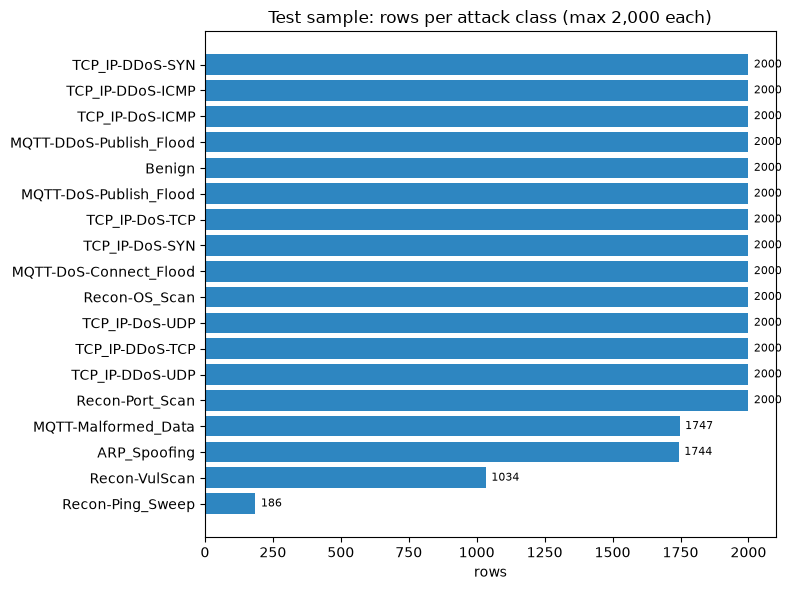

In [4]:
counts = y_test.value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(counts.index, counts.values, color="#2e86c1")
for y, v in enumerate(counts.values):
    ax.text(v + 20, y, str(v), va="center", fontsize=8)
ax.set_xlabel("rows"); ax.set_title("Test sample: rows per attack class (max 2,000 each)")
plt.tight_layout(); plt.show()

## Cell 5: Detector Accuracy and Classification Report

In [5]:
from sklearn.metrics import classification_report, accuracy_score, f1_score
pred = model.predict(X_test)
acc = accuracy_score(y_test, pred)
macro_f1 = f1_score(y_test, pred, average="macro", zero_division=0)
print(f"Accuracy: {acc:.4f} | Macro F1: {macro_f1:.4f}\n")
print(classification_report(y_test, pred, zero_division=0))

Accuracy: 0.8855 | Macro F1: 0.8518

                         precision    recall  f1-score   support

           ARP_Spoofing       0.68      0.95      0.79      1744
                 Benign       0.77      0.91      0.84      2000
MQTT-DDoS-Publish_Flood       0.99      0.13      0.23      2000
 MQTT-DoS-Connect_Flood       1.00      1.00      1.00      2000
 MQTT-DoS-Publish_Flood       0.54      1.00      0.70      2000
    MQTT-Malformed_Data       0.98      0.76      0.85      1747
          Recon-OS_Scan       0.79      0.86      0.82      2000
       Recon-Ping_Sweep       0.99      0.69      0.82       186
        Recon-Port_Scan       0.94      0.96      0.95      2000
          Recon-VulScan       0.98      0.23      0.38      1034
       TCP_IP-DDoS-ICMP       1.00      1.00      1.00      2000
        TCP_IP-DDoS-SYN       1.00      0.97      0.98      2000
        TCP_IP-DDoS-TCP       1.00      1.00      1.00      2000
        TCP_IP-DDoS-UDP       1.00      0.99      1.

## Cell 6: Confusion Matrix
Rows = true attack, columns = predicted attack. A bright diagonal means correct. Numbers are row percentages.

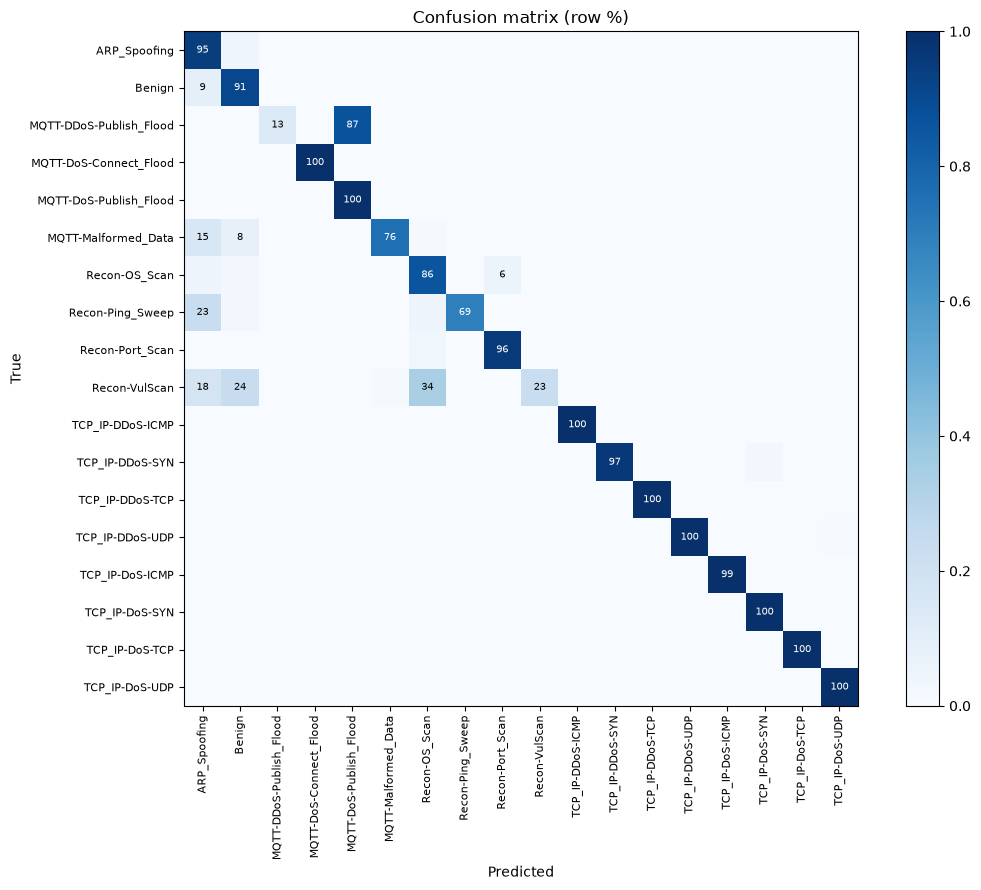

In [6]:
from sklearn.metrics import confusion_matrix
labels = sorted(set(y_test) | set(pred))
cm = confusion_matrix(y_test, pred, labels=labels)
cm_pct = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=90, fontsize=8); ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (row %)")
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm_pct[i, j] >= 0.05:
            ax.text(j, i, f"{cm_pct[i, j]*100:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if cm_pct[i, j] > 0.5 else "black")
fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.show()

## Cell 7: F1-score per Attack Class
Red bars are below 0.8. These weak classes belong to the stand-in detector (Component 2's job), not to Component 3.

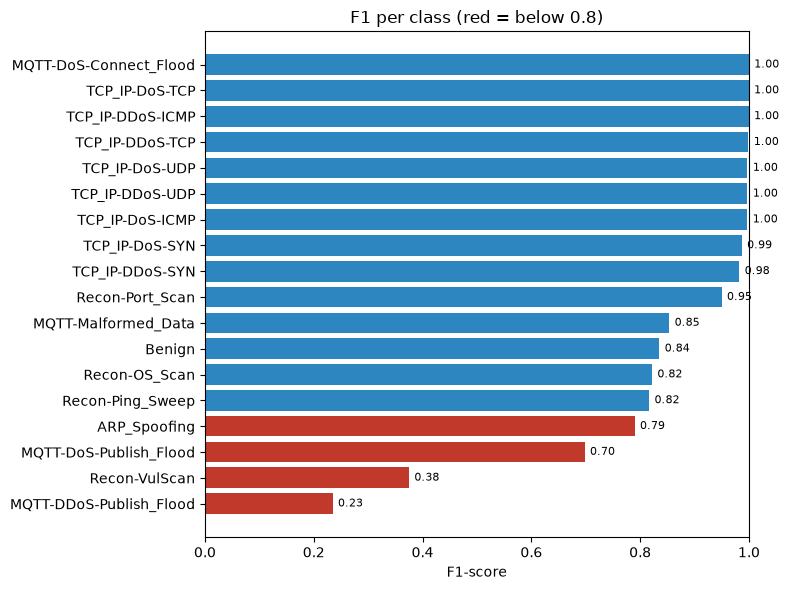

In [7]:
f1 = pd.Series(f1_score(y_test, pred, labels=labels, average=None, zero_division=0), index=labels).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(f1.index, f1.values, color=["#c0392b" if v < 0.8 else "#2e86c1" for v in f1.values])
ax.set_xlim(0, 1); ax.set_xlabel("F1-score"); ax.set_title("F1 per class (red = below 0.8)")
for y, v in enumerate(f1.values):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

## Cell 8: SHAP Explanation for One Attack
SHAP shows which features pushed the model toward its decision. Blue pushes toward the predicted attack, red pushes away. Component 3 sends the top 3 to Component 4.

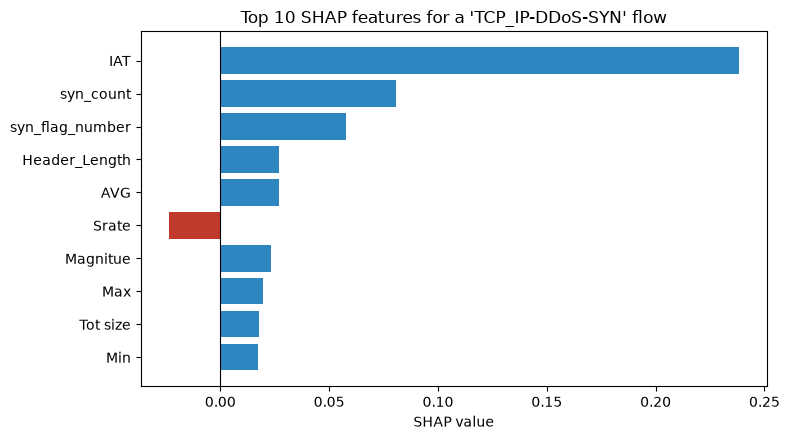

Top 3 sent to Component 4: [{'feature': 'IAT', 'shap_value': 0.2381}, {'feature': 'syn_count', 'shap_value': 0.0806}, {'feature': 'syn_flag_number', 'shap_value': 0.0578}]


In [8]:
explainer = Explainer(model, top_k=10)
attack = "TCP_IP-DDoS-SYN" if "TCP_IP-DDoS-SYN" in set(y_test) else y_test.iloc[0]
row = test[test["label"] == attack].iloc[0]
x = [float(row[c]) for c in FEATURES]
top, total = explainer.analyse(x, attack)

names  = [t["feature"] for t in top][::-1]
values = [t["shap_value"] for t in top][::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(names, values, color=["#2e86c1" if v > 0 else "#c0392b" for v in values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title(f"Top 10 SHAP features for a '{attack}' flow"); ax.set_xlabel("SHAP value")
plt.tight_layout(); plt.show()
print("Top 3 sent to Component 4:", top[:3])

## Cell 9: Severity Decisions and the Life-Critical Override
Same attack, different devices. Life-critical devices are forced to **Critical** with the protection flag, whatever the attack.

In [9]:
engine = SeverityEngine(mode="rule")
attacks = ["Recon-Ping_Sweep", "Recon-OS_Scan", "TCP_IP-DoS-SYN", "TCP_IP-DDoS-SYN"]
devices = list(DEVICES)
life = [d for d in devices if taxonomy.device_is_life_critical(d)]
print("Life-critical devices:", life, "\n")

pd.DataFrame(
    {dev: [engine.decide(a, 0.90, 0.0, dev)[0] for a in attacks] for dev in devices},
    index=attacks,
)

Life-critical devices: ['ventilator_01', 'insulin_pump_01', 'infusion_pump_01'] 



,ventilator_01,insulin_pump_01,infusion_pump_01,cardiac_monitor_01,bp_monitor_01,patient_server_01,admin_server_01
Recon-Ping_Sweep,Critical,Critical,Critical,Low,Low,Low,Low
Recon-OS_Scan,Critical,Critical,Critical,Medium,Medium,Medium,Medium
TCP_IP-DoS-SYN,Critical,Critical,Critical,High,High,High,High
TCP_IP-DDoS-SYN,Critical,Critical,Critical,Critical,Critical,Critical,Critical


## Cell 10: Processing Time
Time Component 3 needs to explain one detection (SHAP) and decide its severity. Target: under 100 ms.

requests: 185 | median: 45.7 ms | p90: 48.3 ms | max: 63.4 ms


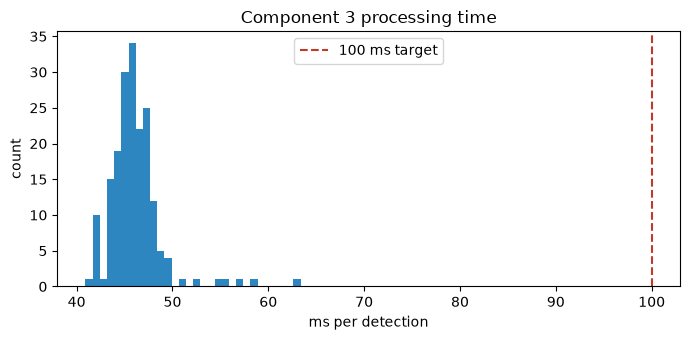

In [10]:
sample = test.sample(min(200, len(test)), random_state=0)
explainer3 = Explainer(model, top_k=3)
explainer3.analyse([float(sample.iloc[0][c]) for c in FEATURES], sample.iloc[0]["label"])   # warm-up

times = []
for _, r in sample.iterrows():
    cls = r["label"]
    if cls not in taxonomy.ATTACK_SEVERITY:
        continue
    x = [float(r[c]) for c in FEATURES]
    t0 = time.perf_counter()
    top, mag = explainer3.analyse(x, cls)
    engine.decide(cls, 0.9, mag, "bp_monitor_01")
    times.append((time.perf_counter() - t0) * 1000)

times = np.array(times)
print(f"requests: {len(times)} | median: {np.median(times):.1f} ms | p90: {np.percentile(times, 90):.1f} ms | max: {times.max():.1f} ms")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(times, bins=30, color="#2e86c1"); ax.axvline(100, color="#c0392b", ls="--", label="100 ms target")
ax.set_xlabel("ms per detection"); ax.set_ylabel("count"); ax.legend(); ax.set_title("Component 3 processing time")
plt.tight_layout(); plt.show()

## Cell 11: Final Summary

In [11]:
weak = f1.head(3)
summary = pd.DataFrame({
    "Item": [
        "Detector (stand-in) accuracy",
        "Detector macro F1",
        "Weakest classes (F1)",
        "Contract features used",
        "Life-critical devices (forced Critical)",
        "SHAP + severity time (median / p90)",
        "Under 100 ms target",
    ],
    "Result": [
        f"{acc:.1%} on {len(test)} real test rows",
        f"{macro_f1:.3f}",
        ", ".join(f"{k} ({v:.2f})" for k, v in weak.items()),
        str(len(FEATURES)),
        ", ".join(life),
        f"{np.median(times):.1f} ms / {np.percentile(times, 90):.1f} ms",
        "Yes" if np.percentile(times, 90) < 100 else "No",
    ],
})
print(summary.to_string(index=False))

                                   Item                                                                              Result
           Detector (stand-in) accuracy                                                       88.6% on 32711 real test rows
                      Detector macro F1                                                                               0.852
                   Weakest classes (F1) MQTT-DDoS-Publish_Flood (0.23), Recon-VulScan (0.38), MQTT-DoS-Publish_Flood (0.70)
                 Contract features used                                                                                  45
Life-critical devices (forced Critical)                                    ventilator_01, insulin_pump_01, infusion_pump_01
    SHAP + severity time (median / p90)                                                                   45.7 ms / 48.3 ms
                    Under 100 ms target                                                                                 Yes


### Notes
- The detector is a **stand-in** Random Forest. Component 2's real model will replace `models/detector.joblib`.
- Weak classes belong to the stand-in detector, not to Component 3.
- The severity table is rule-based and still needs supervisor approval.